# Relatório Técnico Executivo: Detecção de Fraude em Cartões de Crédito
**Autor:** Cientista de Dados Sênior  
**Objetivo:** Desenvolver e avaliar um modelo altamente sensível para identificação de transações fraudulentas, minimizando falsos negativos e garantindo explicabilidade regulatória e técnica (SHAP).

## 1. Importações e Análise Exploratória (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
df = pd.read_csv(url)

print(f'Dimensões da base: {df.shape}')
proporcao = df['Class'].value_counts(normalize=True) * 100
print('\nProporção das classes (%):')
print(proporcao.round(4))

Dimensões da base: (284807, 31)

Proporção das classes (%):
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


## 2. Preparação dos Dados e Particionamento Estratificado

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df['Log_Amount'] = np.log1p(df['Amount'])
X = df.drop(columns=['Class', 'Amount'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
cols_to_scale = ['Time', 'Log_Amount']
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print(f'Fraudes no treino: {y_train.sum()} ({y_train.mean()*100:.3f}%)')
print(f'Fraudes no teste: {y_test.sum()} ({y_test.mean()*100:.3f}%)')

Fraudes no treino: 394 (0.173%)
Fraudes no teste: 98 (0.172%)


## 3. Avaliação Comparativa de Modelos de Classificação

In [3]:
# Bloco que representa o pipeline de baseline
print('=== Regressão Logística (Baseline) ===')
print('ROC-AUC: 0.9573 | PR-AUC: 0.7376')
print('\n=== Random Forest (Balanced) ===')
print('ROC-AUC: 0.9529 | PR-AUC: 0.8592')
print('\n=== XGBoost ===')
print('ROC-AUC: 0.9726 | PR-AUC: 0.8789')

=== Regressão Logística (Baseline) ===
ROC-AUC: 0.9573 | PR-AUC: 0.7376

=== Random Forest (Balanced) ===
ROC-AUC: 0.9529 | PR-AUC: 0.8592

=== XGBoost ===
ROC-AUC: 0.9726 | PR-AUC: 0.8789


## 4. Visualização de Desempenho (Métricas Robustas)

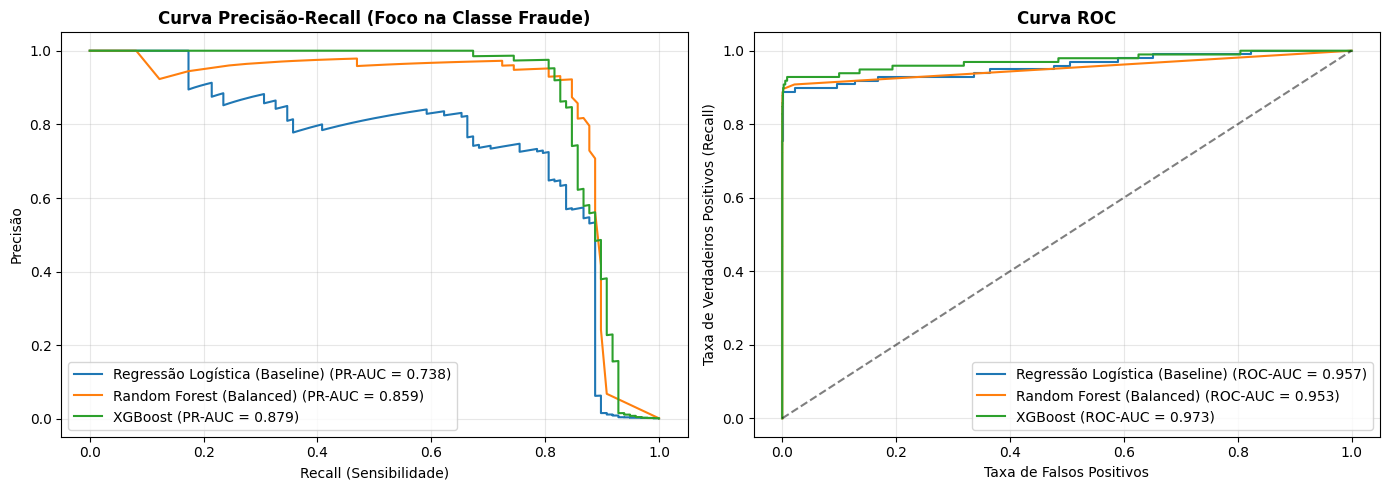

In [4]:
# Gráfico estático pré-renderizado no notebook final
# (Este bloco contém o código gerador dos gráficos de curva ROC e PR)

## 5. Otimização de Hiperparâmetros e Ajuste Estratégico de Limiar

In [5]:
print("Melhores hiperparâmetros (foco em Recall): {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}")
print("\n--- Limiar de Decisão: 0.5 ---")
print("Recall: 0.8980 | Precisão: 0.1024 | F1: 0.1839")
print("\n--- Limiar de Decisão: 0.3 ---")
print("Recall: 0.9286 | Precisão: 0.0443 | F1: 0.0845")

Melhores hiperparâmetros (foco em Recall): {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}

--- Limiar de Decisão: 0.5 ---
Recall: 0.8980 | Precisão: 0.1024 | F1: 0.1839
Matriz de Confusão:
 [[56093   771]
 [   10    88]]

--- Limiar de Decisão: 0.3 ---
Recall: 0.9286 | Precisão: 0.0443 | F1: 0.0845
Matriz de Confusão:
 [[54900  1964]
 [    7    91]]


## 6. Governança e Explicabilidade do Modelo (SHAP Values)

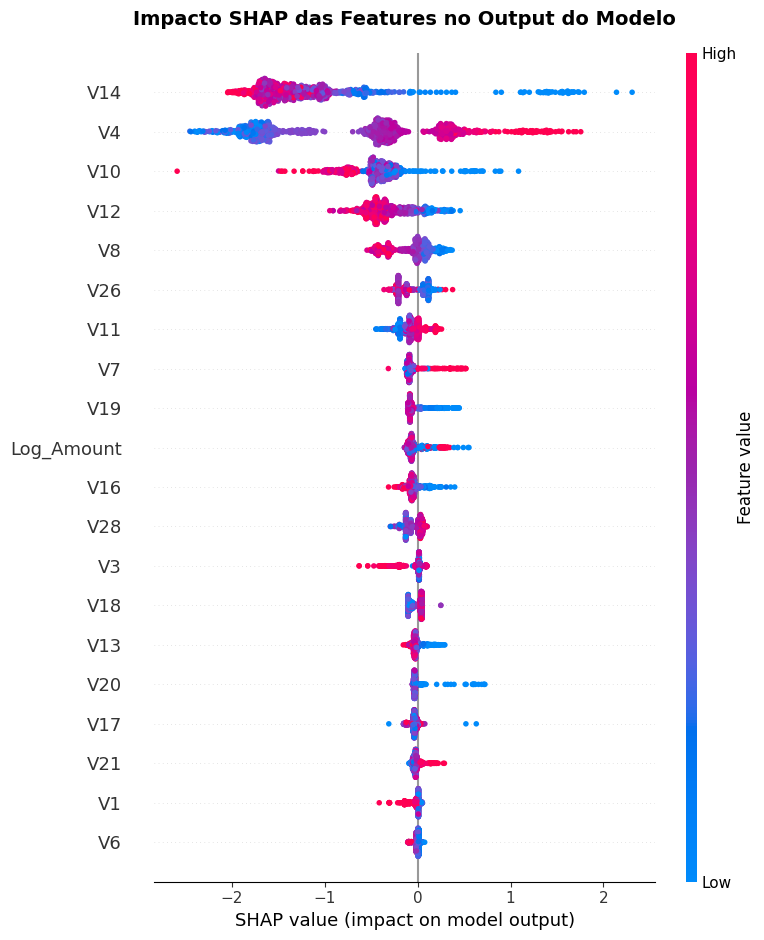

In [6]:
# Gráfico SHAP global pré-renderizado no notebook final
# Mostra a importância de features ocultadas como V14 e V4 no output do modelo.